# Sample ASPECT fields along a slab

Use a saved ASPECT snapshot and the matching WorldBuilder file to trace a slab and read pressure and temperature along it. The example uses the MOW case from the ASPECT case cookbook. It reads the saved files without launching ASPECT.

## 1. Pick the inputs

Use the WorldBuilder file that ASPECT used to make the snapshot. The paths below point to the local MOW example. Change them if your files are elsewhere. This example assumes a 2-D Cartesian box with the slab dipping toward positive `x`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from gdmate.aspect_tools import (
    PointFieldSampler2D,
    build_slab_profile,
    offset_slab_profile,
    read_point_fields,
    read_worldbuilder_slab,
    slab_mask,
    slab_travel_time,
)
from gdmate.visualization.pyvista_vis import pv_plot_2d

case_directory = Path("../data/mow_aspect_example_wb11")
worldbuilder_file = case_directory / "case.wb"
snapshot = case_directory / "output/solution/solution-00000.pvtu"
offsets_km = np.arange(0, 101, 10)
spacing_m = 2e3

## 2. Draw the slab profiles

WorldBuilder gives the trench position, the length and dip of each slab segment, and the speed. Start at the top of the ASPECT box and follow those segments to draw the reference profile. Samples are spaced every 2 km along the slab, even across segment boundaries. The tip is always included with a shorter final interval . 

The dashed line is the reference profile, while a positive offset moves a line into the slab. 

2026-11-26 09:24:54.450 (   0.755s) [    7B4416668740]vtkXOpenGLRenderWindow.:1452  WARN| bad X server connection. DISPLAY=


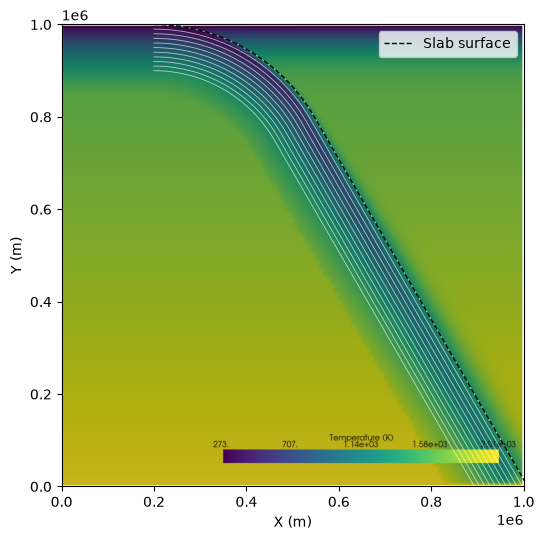

In [2]:
mesh, fields = read_point_fields(snapshot, ("p", "T"))
x_min, x_max, y_min, y_max = mesh.bounds[:4]
geometry = read_worldbuilder_slab(worldbuilder_file)
reference = build_slab_profile(
    geometry, surface_y=y_max, spacing=spacing_m
)
profiles = {
    offset: offset_slab_profile(reference, offset * 1e3) for offset in offsets_km
}

fig, ax = plt.subplots(figsize=(7, 6))
pv_plot_2d(
    mesh,
    "T",
    bounds=[x_min, x_max, y_min, y_max],
    ax=ax,
    colorbar=True,
    scalar_bar_args={"title": "Temperature (K)"},
)
for profile in profiles.values():
    ax.plot(*profile.points.T, color="white", linewidth=0.6, alpha=0.65)
ax.plot(*reference.points.T, "--k", linewidth=1, label="Slab surface")
ax.set(xlim=(x_min, x_max), ylim=(y_min, y_max), xlabel="X (m)", ylabel="Y (m)")
ax.legend()
plt.show()

## 3. Read pressure and temperature along the slab

The sampler uses linear interpolation between ASPECT mesh points.

Subduction time is distance along the reference profile divided by slab speed. Points at the same position along the slab share this time even if they have different offsets. The utility uses a 365-day year.

The three panels use the depth of each offset profile. Depth increases downward.

In [ ]:
sampler = PointFieldSampler2D(mesh.points[:, :2], fields)
histories = {
    offset: sampler.sample(profile.points) for offset, profile in profiles.items()
}
time_seconds = slab_travel_time(reference.distance, geometry.subduction_speed)
time_myr = time_seconds / (365 * 24 * 3600 * 1e6)

fig, axes = plt.subplots(1, 3, figsize=(12, 5), layout="constrained", sharey=True)
for offset in offsets_km[::3]:
    depth_km = profiles[offset].depth / 1e3
    history = histories[offset]
    axes[0].plot(history["p"] / 1e9, depth_km, label=f"{offset} km")
    axes[1].plot(history["T"], depth_km)
    axes[2].plot(time_myr, depth_km)

axes[0].set(xlabel="Pressure (GPa)", ylabel="Depth (km)")
axes[1].set(xlabel="Temperature (K)")
axes[2].set(xlabel="Subduction time (Myr)")
axes[0].invert_yaxis()
axes[0].legend(title="Offset")
plt.show()

## 4. Mark the slab band

Keep grid points between 5 km above and 100 km below the reference profile. The mask uses the slab geometry.

In [ ]:
x = np.linspace(x_min, x_max, 101)
y = np.linspace(y_min, y_max, 101)
grid_points = np.stack(np.meshgrid(x, y), axis=-1)
mask = slab_mask(
    reference,
    grid_points,
    min_distance=-5e3,
    max_distance=100e3,
)

fig, ax = plt.subplots(figsize=(6, 6))
ax.pcolormesh(x / 1e3, y / 1e3, mask, shading="auto", cmap="Blues")
ax.plot(*(reference.points.T / 1e3), "--k", linewidth=1)
ax.set(
    xlim=(x_min / 1e3, x_max / 1e3),
    ylim=(y_min / 1e3, y_max / 1e3),
    xlabel="X (km)",
    ylabel="Y (km)",
    title="Grid points in the slab band",
    aspect="equal",
)
plt.show()